# 03 · Vector search for real

In notebook 01 we kept eight vectors in a numpy array and compared the question against all of
them. That doesn't scale to millions of chunks, and it forgets everything when the kernel stops.
A **vector database** stores chunks with their vectors and metadata on disk, and finds nearest
neighbours quickly. We'll use **Chroma**, which runs locally with no server.

**In this notebook you will:**
- see what a stored record looks like (id, vector, text, metadata),
- query by meaning and read the distances,
- filter by metadata ("only hotels in Asia"),
- compare plain top-k with **MMR**, which trades a little relevance for variety,
- understand how every notebook gets its index without re-running earlier notebooks.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: build (or reuse) this notebook's index: the whole corpus, chunked as in notebook 02
from raglab.bootstrap import ensure_raw_collection

collection = ensure_raw_collection("nb03_raw")

[nb03_raw] reusing index (103 chunks)


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. What's in a collection?

A **collection** is like a table. Each record has an `id`, an `embedding` (the vector), a
`document` (the chunk text) and `metadata` (whatever we attached in notebook 02).

In [4]:
print(f"{collection.count()} records")
record = collection.get(limit=1, offset=40, include=["documents", "metadatas", "embeddings"])
print("id:       ", record["ids"][0])
print("metadata: ", record["metadatas"][0])
print("document: ", record["documents"][0][:200].replace("\n", " "), "…")
print("embedding:", len(record["embeddings"][0]), "numbers, starting", [round(float(x), 3) for x in record["embeddings"][0][:4]])

103 records
id:        bd85358d627cb4c0
metadata:  {'has_spa': False, 'source_file': 'hotel_profiles.pdf', 'page': 3, 'continent': 'Europe', 'has_pool': False, 'star_rating': 3, 'city': 'Reykjavík', 'price_per_night': 190, 'hotel_name': 'Token Reykjavík', 'country': 'Iceland', 'doc_type': 'profile'}
document:  Token Reykjavík — profile  Token Reykjavík. The Flybus from Keflavík Airport stops outside the entrance and costs $35 per person. Feature Token Reykjavík Location Reykjavík, Iceland (Europe) Star rati …
embedding: 1536 numbers, starting [-0.017, -0.035, -0.005, -0.028]


The id is a hash of the file name and chunk text (`store_chroma.chunk_id`), so the same chunk
always gets the same id. That will matter in notebook 09, when we update the index instead of
rebuilding it.

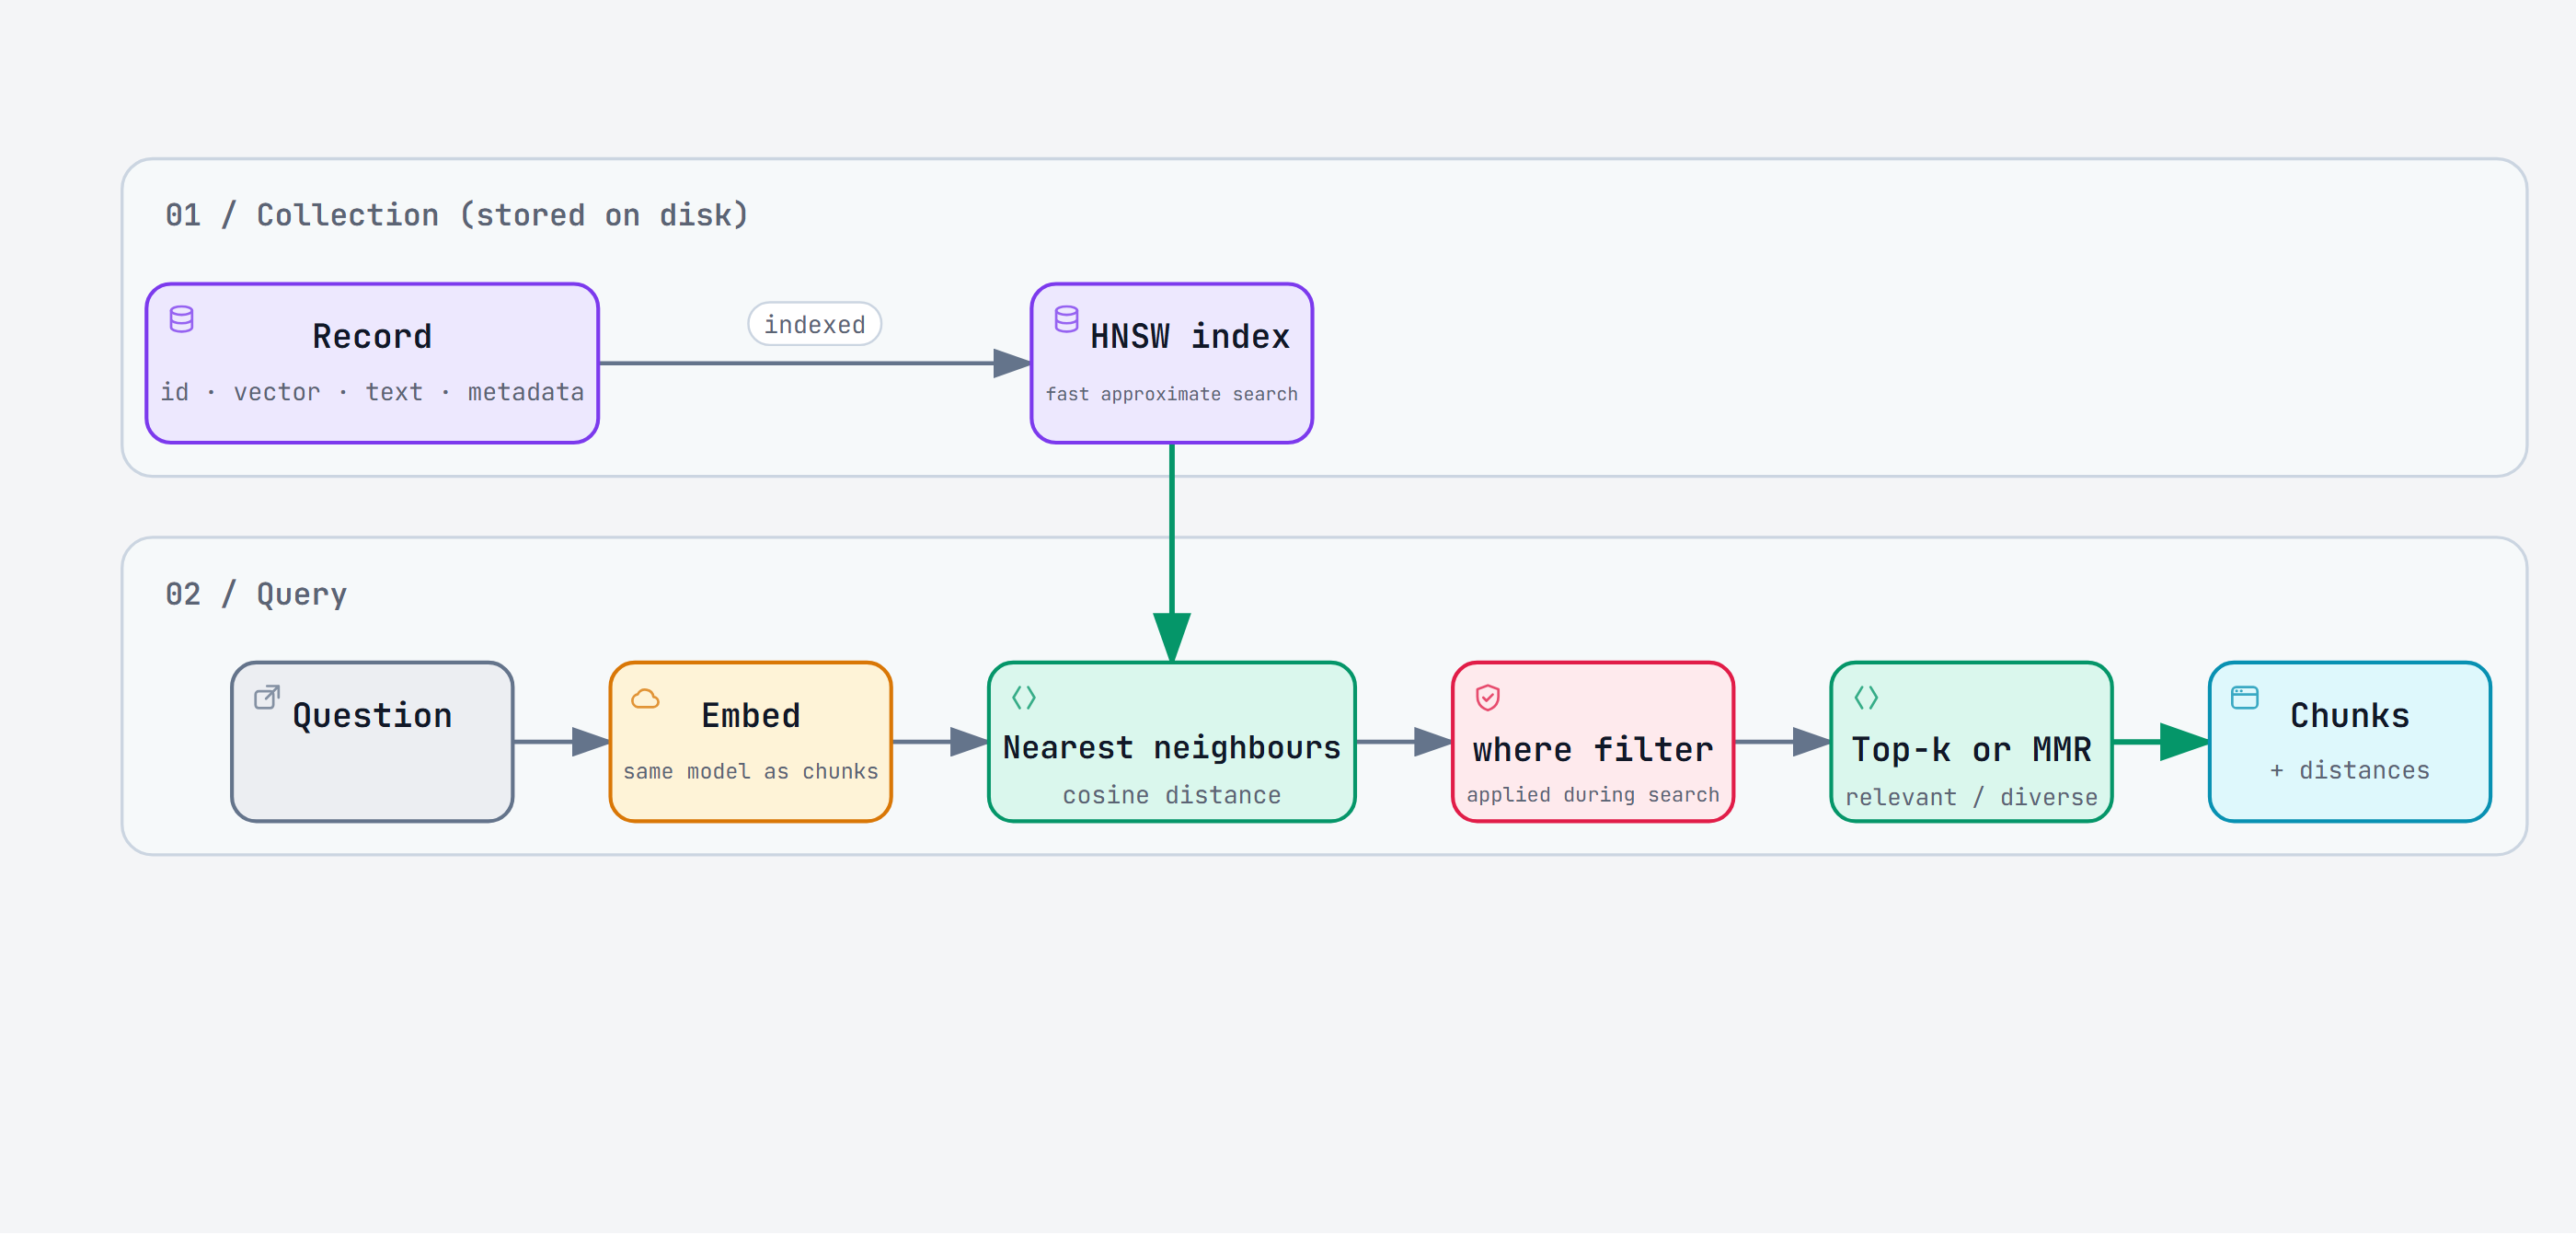

[Open interactive version](../diagrams/vector_search.html)

In [5]:
from raglab.display import show_diagram

show_diagram("vector_search")

## 2. Query by meaning

`store_chroma.query` embeds the question and asks Chroma for the k nearest records. Chroma
reports a **distance**: here `1 - cosine similarity`, so **smaller is closer**.

In [6]:
from raglab import store_chroma


def show_hits(hits):
    for doc, distance in hits:
        meta = doc.metadata
        label = meta.get("hotel_name") or "-"
        print(f"{distance:.3f}  {meta['source_file']:<22}{label:<18}{doc.page_content[:70].replace(chr(10), ' ')}")


show_hits(store_chroma.query(collection, "What time is check-in at Token Kyoto?", k=4))

0.257  hotel_profiles.pdf    Token Kyoto       Token Kyoto — profile  Check-in at Token Kyoto starts at 4:00 PM and c
0.347  room_rates.csv        Token Kyoto       Token Kyoto — rates  hotel: Token Kyoto city: Kyoto room_type: Suite s
0.352  room_rates.csv        Token Kyoto       Token Kyoto — rates  hotel: Token Kyoto city: Kyoto room_type: Suite s
0.358  room_rates.csv        Token Kyoto       Token Kyoto — rates  hotel: Token Kyoto city: Kyoto room_type: Deluxe 


The right chunk comes first. Compare the distances of a question that's related to our
documents with one that isn't:

In [7]:
for q in ["Which restaurant serves Moroccan food?", "How do I change a bicycle tyre?"]:
    best = store_chroma.query(collection, q, k=1)[0][1]
    print(f"{best:.3f}  {q}")

0.339  Which restaurant serves Moroccan food?
0.845  How do I change a bicycle tyre?


The unrelated question's *best* match is much further away. Distance is a useful signal for
"we probably don't have this", but the right threshold depends on the embedding model and the
corpus, so measure it before relying on it.

Notice also how many results above come from `room_rates.csv`. Each of its 48 rows is a chunk
that names a hotel, so rate rows crowd into results for any hotel-specific question. Structured
data like this often deserves its own tool rather than the vector index (notebook 12).

## 3. Filter by metadata

Because we attached metadata in notebook 02, we can restrict the search. Chroma applies the
filter during the search, so you still get k results that all match it.

In [8]:
show_hits(store_chroma.query(collection, "a hotel with a spa", k=4, where={"continent": "Asia"}))

0.606  hotel_profiles.pdf    Token Kyoto       Token Kyoto — profile  Check-in at Token Kyoto starts at 4:00 PM and c
0.649  room_rates.csv        Token Singapore   Token Singapore — rates  hotel: Token Singapore city: Singapore room_t
0.654  room_rates.csv        Token Singapore   Token Singapore — rates  hotel: Token Singapore city: Singapore room_t
0.661  room_rates.csv        Token Singapore   Token Singapore — rates  hotel: Token Singapore city: Singapore room_t


Filters can combine conditions with `$and` / `$or` and compare numbers with `$lt`, `$gte`, and so on:

In [9]:
cheap_with_pool = {"$and": [{"has_pool": True}, {"price_per_night": {"$lt": 300}}]}
show_hits(store_chroma.query(collection, "swimming pool", k=3, where=cheap_with_pool))

0.748  guest_reviews.md      Token Lisbon      Token Lisbon — reviews  ## Token Lisbon  "The rooftop pool at sunset w
0.837  hotel_profiles.pdf    Token Lisbon      Token Lisbon — profile  Token Hotels & Resorts - Property Guide 2025 T
0.870  room_rates.csv        Token Lisbon      Token Lisbon — rates  hotel: Token Lisbon city: Lisbon room_type: Suit


A filter is only as good as the metadata behind it. Chunks that `enrich_metadata` couldn't assign
to a single hotel (for example a PDF chunk spanning two hotels) have no `continent` or
`has_pool`, so a filter silently excludes them.

## 4. Persistence

The collection lives in `.cache/chroma` on disk. A brand-new client sees the same data, with no
re-embedding needed:

In [10]:
fresh_client = store_chroma.get_client()
print(fresh_client.get_collection("nb03_raw").count(), "records found by a new client")

103 records found by a new client


## 5. Top-k vs MMR: relevance vs variety

Plain top-k returns the k *most similar* chunks, and they're often near-duplicates of each other.
For a broad question ("which hotels have a spa?") you want **coverage**: several different hotels,
not three slices of the same one.

**Maximal Marginal Relevance (MMR)** picks results one at a time. Each pick maximises

`λ · similarity(question, chunk) − (1 − λ) · max similarity(chunk, already picked)`

so a chunk that repeats what we already have gets penalised. `λ = 1` is plain top-k.

In [11]:
def sources(docs):
    return [d.metadata["source_file"] for d in docs]


question = "What is Token Marrakech like?"
plain = [d for d, _ in store_chroma.query(collection, question, k=5)]
mmr = store_chroma.query_mmr(collection, question, k=5, fetch_k=25, lambda_mult=0.5)
print("top-k:", sources(plain))
print("MMR:  ", sources(mmr))

top-k: ['hotel_profiles.pdf', 'guest_reviews.md', 'room_rates.csv', 'room_rates.csv', 'room_rates.csv']
MMR:   ['hotel_profiles.pdf', 'dining_guide.md', 'guest_reviews.md', 'dining_guide.md', 'faq.html']


Plain top-k spends three of its five slots on near-identical rows of `room_rates.csv`. MMR keeps
the best match, then swaps the repeats for *different* documents (dining, reviews, FAQ), which is a
better basis for a "what is it like?" answer.

MMR isn't always better. When the question really is about those rows, repetition is what you want:

In [12]:
question = "How much does a room at Token Singapore cost?"
print("top-k:", sources([d for d, _ in store_chroma.query(collection, question, k=5)]))
print("MMR:  ", sources(store_chroma.query_mmr(collection, question, k=5, fetch_k=25, lambda_mult=0.5)))

top-k: ['room_rates.csv', 'room_rates.csv', 'room_rates.csv', 'room_rates.csv', 'room_rates.csv']
MMR:   ['room_rates.csv', 'dining_guide.md', 'hotel_profiles.pdf', 'guest_reviews.md', 'hotel_profiles.pdf']


Here MMR throws away rate rows (different room types and seasons) in favour of loosely related
chunks. Use MMR for broad, exploratory questions and plain top-k for precise lookups, or better,
*measure* which works for your questions (notebook 05).

## 6. How every notebook gets its index

Setup cell 2 called `ensure_raw_collection("nb03_raw")`. It:

1. computes a **fingerprint**: a hash of the profile's settings (chunk size, overlap…) and of every corpus file,
2. reuses the collection if its stored fingerprint matches,
3. otherwise rebuilds it. Thanks to the embedding cache, a rebuild only pays for chunks it has never seen.

That's why you can open notebook 07 without running notebooks 03–06 first. Each notebook asks
for the index it needs by name, and names never change meaning.

In [13]:
from raglab import bootstrap

print("fingerprint:", bootstrap.corpus_fingerprint("nb03_raw"))
print("stored:     ", collection.metadata.get("fingerprint"))

fingerprint: d7605a266e5805c07026
stored:      d7605a266e5805c07026


## Your turn

1. Query `"late checkout"` with `k=5`. Which documents answer it? Do any results look like noise?
2. Find all 5-star hotels with a pool using only a `where` filter (any query text will do).
   Which hotels do you get, and are any missing? Why might they be?
3. Run the Marrakech MMR comparison with `lambda_mult=0.2` and `0.9`. What changes?

<details><summary>Hints</summary>

2. `where={"$and": [{"star_rating": 5}, {"has_pool": True}]}`. Expect Token Marrakech and Token
   Singapore. Hotels can only appear if at least one of their chunks carries the metadata; see section 3.
3. Lower λ → more variety (and more off-topic chunks); higher λ → closer to plain top-k.
</details>

## Key takeaways

- A vector store keeps id + vector + text + metadata and answers "nearest neighbours" fast.
- Distances tell you how close a match is; metadata filters narrow the search.
- MMR balances relevance and diversity, which helps broad questions.
- Named, fingerprinted index profiles make every notebook standalone.

**Added to raglab:** `store_chroma.get_client / create_collection / query / query_mmr / chunk_id`,
`bootstrap.IndexProfile / PROFILES / corpus_fingerprint / build_chunks / ensure_raw_collection`.

In [14]:
cost.report()

Cost: no API calls in this notebook ($0.0000)
